# Mendeley

## Project Description

### Goal:
- build a simple


###  Data Pre-processing (10%)
- Missing values / outliers : Robust and nuanced approach
- Categorical encoding : Advanced or balanced encoding strategies
- Scaling numerical features : Method adapted to model needs

### Feature Selection and Creation (5%)
- Relevant feature selection : Justified selection using data or domain logic Optimal features chosen via analysis
- Feature transformation / creation (Optional depending on the necessity) : Useful engineered features Innovative and insightful feature creation.

### Model Comparison and Hyperparameter Selection (25%)
- Dataset splitting : train/val/test split and crossvalidation
- Model training : more than 3 models tested (among which one deep learning model) with choice justification.
- Performance comparison : In-depth multi-metric evaluation
- Hyperparameter selection/tuning : Advanced tuning with crossvalidation
- Over/underfitting analysis : Correct analysis with remedies, Deep, justified understanding

### Presentation of Results (20%)


### Report :
- EDA requires multiple graphs to be complete.
- When evaluating your failure prediction model, use a baseline (for example, the naive average of the students’ grades). This allows you to compare your model with a very simple ”worst-case” model and determine whether your approach performs better.


## 1. Setup & Imports:

In [7]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The zip nested everything inside a "Datasets/" folder
DATA_DIR = Path("..").resolve() / "datasets" / "mendeley" / "Datasets"

print("Python:", sys.executable)
print("Data dir:", DATA_DIR)
print("Exists:  ", DATA_DIR.exists())
for f in sorted(DATA_DIR.glob("*.csv")):
    print(f"  {f.name:55s} {f.stat().st_size / 1024**2:8.2f} MB")


datasets = {}

Python: /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/fedora-venv/bin/python
Data dir: /home/vass/devp/KUL/deep-learning-KUL/federated-neural-network-cluster/datasets/mendeley/Datasets
Exists:   True
  PCs_devices_dataset_for_testing.csv                         4.59 MB
  PCs_devices_dataset_for_training.csv                        8.98 MB
  iot_devices_dataset_for_testing.csv                         2.46 MB
  iot_devices_dataset_for_training.csv                        6.82 MB


## 2. Data Exploration

### 2.1 Raw Data Overview

We start by inspecting the raw dataset before making any preprocessing decisions. This is important because it lets us understand the original structure of the data and identify possible issues such as missing values, identifiers, and variable types.

In [12]:
iot_train = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_training.csv")
print("shape:", iot_train.shape)
print("\ndtypes:\n", iot_train.dtypes.value_counts())
# iot_train.head()

shape: (30000, 43)

dtypes:
 int64      30
str         7
float64     6
Name: count, dtype: int64


#### Check data balance

In [13]:
iot_test = pd.read_csv(DATA_DIR / "iot_devices_dataset_for_testing.csv")
pc_test  = pd.read_csv(DATA_DIR / "PCs_devices_dataset_for_testing.csv")

for name, df in [("IoT test", iot_test), ("PC test", pc_test)]:
    label_col = [c for c in df.columns if c.lower() in ("attack", "label", "class")][0]
    print(f"\n{name}: {df.shape}, label column = '{label_col}'")
    print(df[label_col].value_counts(dropna=False))


IoT test: (10000, 46), label column = 'attack'
attack
0    5000
1    5000
Name: count, dtype: int64

PC test: (9883, 46), label column = 'attack'
attack
0    9883
Name: count, dtype: int64


In [14]:
# Save into datasets
datasets["raw"] = {
    "X_train": iot_train.copy(),                    # unlabeled
    "X_test":  iot_test.drop(columns=["attack"]).copy(),
    "y_test":  iot_test["attack"].copy(),
    "description": "Raw: unlabeled training file + labeled test file",
}

#### Feature overview and missing values

In [16]:
raw_X = datasets["raw"]["X_train"]

summary = pd.DataFrame({
    "column": raw_X.columns,
    "dtype": [raw_X[col].dtype for col in raw_X.columns],
    "missing_values": [raw_X[col].isna().sum() for col in raw_X.columns],
    "mean": [
        raw_X[col].mean() if pd.api.types.is_numeric_dtype(raw_X[col]) else None
        for col in raw_X.columns
    ],
    "sample_values": [
        raw_X[col].dropna().unique()[:5] for col in raw_X.columns
    ],
    "cardinality": [raw_X[col].nunique() for col in raw_X.columns],

})

display(summary)


# summary = pd.DataFrame({
#     "dtype": iot_train.dtypes,
#     "n_missing": iot_train.isna().sum(),
#     "n_unique": iot_train.nunique(),
#     "min": iot_train.select_dtypes("number").min(),
#     "max": iot_train.select_dtypes("number").max(),
# })
# summary

,column,dtype,missing_values,mean,sample_values,cardinality
0,pkSeqID,int64,0,15000.500000,"[1, 2, 3, 4, 5]",30000
1,stime,str,0,NaN,[2025-06-07 10:36:17],1
2,flgs,str,0,NaN,"[PA, U]",2
3,flgs_number,int64,0,1.000000,[1],1
4,proto,str,0,NaN,"[SMB, NTP, HTTPS, HTTP, DNS]",9
5,proto_number,int64,0,10.853200,"[6, 17]",2
6,saddr,str,0,NaN,"[192.168.100.11, 192.168.100.12, 192.168.100.1...",6
7,sport,int64,0,33149.807600,"[63010, 60765, 5369, 61780, 37984]",23970
8,daddr,str,0,NaN,"[192.168.100.20, 192.168.100.216, 192.168.100....",348
9,dport,int64,0,705.444833,"[445, 123, 443, 80, 139]",10


### Overview :

#### Group A - constants : 
- `AR_P_Proto_P_Dport` to `TnP_Per_Dport` (19 first rows).
- Also : `flgs_number`(numeric encoding of flgs), `state`, `state_number`, `stime`, `ltime`,
- Constant values
- not useful, dropped.


#### Group B -identifiers :
- `pkSeqID` and `seq`.
- Both are just row indices. Including them would let the model memorise row order rather than learn traffic structure. This is a classic data leakage trap.


#### Group C — High-cardinality categoricals :
- `saddr` : 6 source IPs — probably the 6 testbed devices.
- `daddr` :	348 destination IPs. Too many to one-hot, and they carry almost no generalisable signal.
- `sport` :	23,970 Source Ports. Drop or bucket. Almost every row has a unique source port (ephemeral ports). Bucket into ranges or drop.
- `flgs`  :	Only PA and U in the sample. Use the 2-value string; ignore the broken flgs_number.
- `proto` :	9 protocols (SMB, NTP, HTTPS, HTTP, etc.). One-hot into 9 features, or use proto_number (2 unique values = TCP 6 / UDP 17).


#### Group D — Redundant pairs, keep one of each.
- `sbytes` / `dbytes` : Both n_unique=2351, both min=150, max=2500	Identical distributions. Drop one.
- `spkts` / `dpkts`	: Both n_unique=24, both 2–25	Drop one.
- `srate` / `drate`	: Both n_unique=28268	Drop one.
- `bytes` = `sbytes` + `dbytes` (roughly)	bytes 300–5000, sbytes 150–2500	Keep bytes, drop the two components.

This symmetry is not accidental — it is a strong sign the dataset was synthetically constructed with mirrored source/destination features. Useful for smoke-testing a Flower pipeline, less realistic as intrusion data.


#### Group E — Genuinely informative features :
- `bytes` :	300–5000	total bytes in the flow
- `pkts` :	5–50	total packets in the flow
- `dur` :	0.1–2.5 s	flow duration
- `rate` :	123–48,765	packets per second
- `mean` :	6–1000	mean duration of aggregated sub-flows
- `min` :	40–60	minimum sub-flow duration
- `max` :	500–1000	maximum sub-flow duration
- `stddev` :	0.1–1.5	std-dev of sub-flow durations — 30,000 unique values, looks like noise
- `sum` :	300–5000	sum of sub-flow durations (highly correlated with bytes)
- `proto_number` :	6 or 17	TCP vs. UDP
- `dport` :	10 values	destination port (53, 80, 443, 445, 5683, …)
- `flgs` :	2 values	flow flags (PA, U)

-> those 10–14 features actually carry variation.
--> That gives you roughly 10–12 useful numeric features and 2 low-cardinality categoricals (proto, flgs, or use proto_number + dport and skip flgs).


#### Note :
- stime has n_unique = 1. Every row in the training file shares the same start timestamp.
- Either the training file is a very short capture, or data was synthetically generated or post-processed.
- This dataset has no temporal signal in the training split.
- This dataset can only be used as a smoke test for our Flower pipeline, not a realistic benchmark




### Feature selection

In [22]:
CONSTANT_COLS = [c for c in iot_train.columns if iot_train[c].nunique() <= 1]
ID_COLS       = ["pkSeqID", "seq"]
HIGH_CARD     = ["saddr", "daddr", "sport"]
REDUNDANT     = ["sbytes", "dbytes", "spkts", "dpkts", "srate"]
DROP          = CONSTANT_COLS + ID_COLS + HIGH_CARD + REDUNDANT

clean = iot_train.drop(columns=[c for c in DROP if c in iot_train.columns])
print(f"Kept {clean.shape[1]} of {iot_train.shape[1]} columns")
print(clean.columns.tolist())
print(f"Shape after cleaning: {clean.shape}")

# Dataset holding structure
DROP = CONSTANT_COLS + ID_COLS + HIGH_CARD + REDUNDANT   # your list

datasets["cleaned"] = {
    "train_X": datasets["raw"]["X_train"].drop(columns=DROP).copy(),
    "test_X":  datasets["raw"]["X_test"].drop(columns=DROP).copy(),
    "test_y":  datasets["raw"]["y_test"].copy(),
    "description": "Cleaned: constants/IDs/high-card/redundant dropped"
}






Kept 15 of 43 columns
['flgs', 'proto', 'proto_number', 'dport', 'pkts', 'bytes', 'ltime', 'dur', 'mean', 'stddev', 'sum', 'min', 'max', 'rate', 'drate']
Shape after cleaning: (30000, 15)


### 2.3. EDA plots on raw data

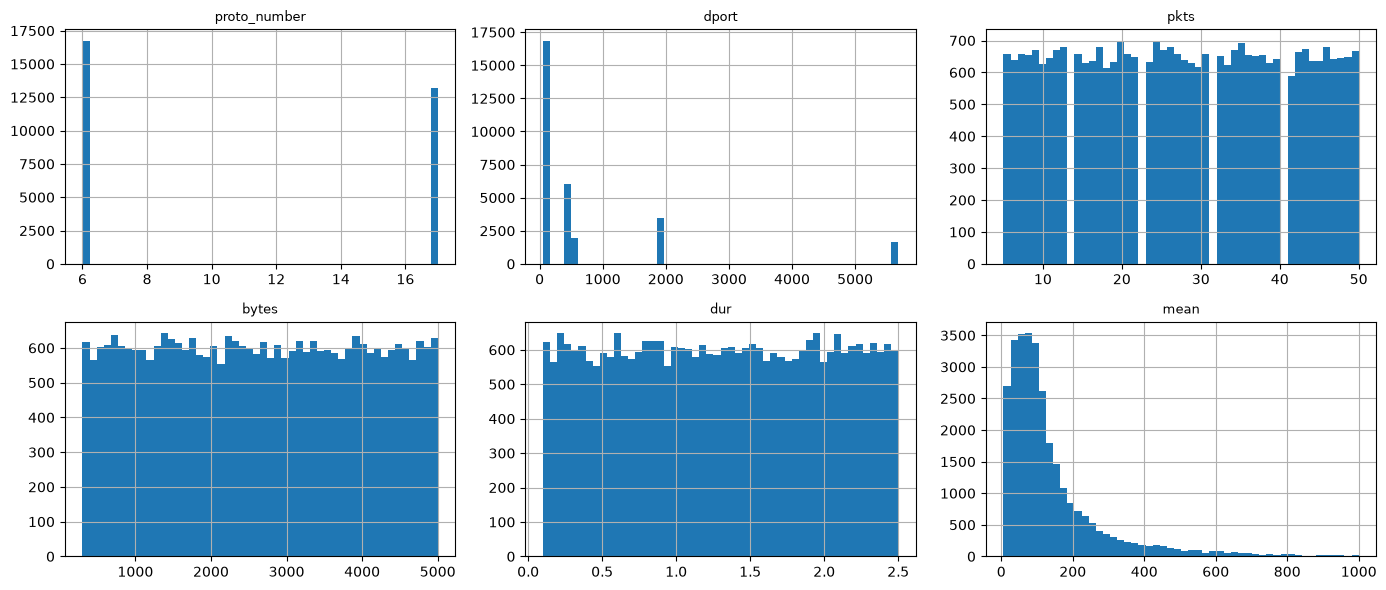

In [ ]:
num_cols = clean.select_dtypes("number").columns.tolist()
to_plot = num_cols[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), to_plot):
    iot_train[col].hist(ax=ax, bins=50)
    ax.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

#### Compare feature distributions: training (benign-dominant) vs. testing (labeled)

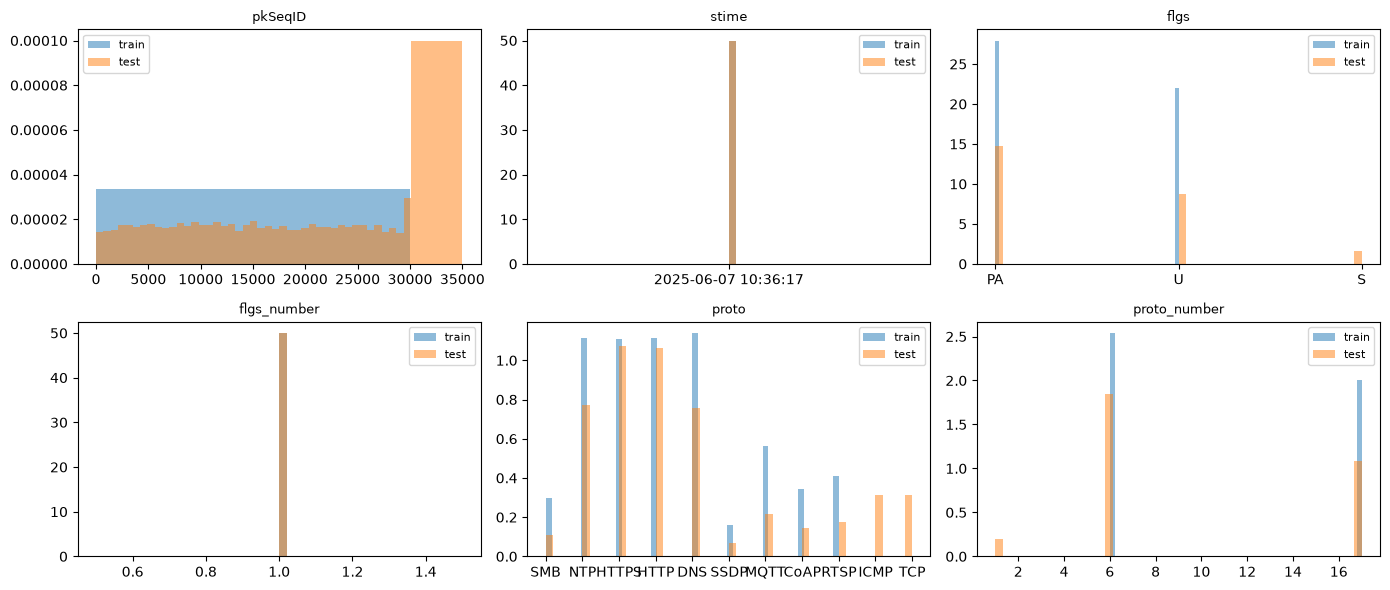

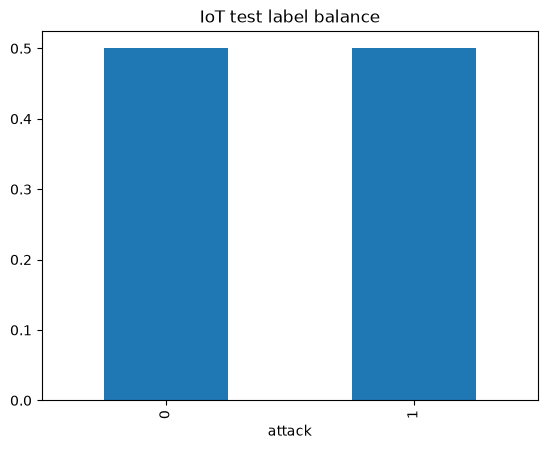

In [ ]:
label_col = [c for c in iot_test.columns if c.lower() in ("attack", "label", "class")][0]
common = [c for c in iot_train.columns if c in iot_test.columns and c != label_col]
sample_cols = common[:6]

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, col in zip(axes.ravel(), sample_cols):
    ax.hist(iot_train[col].dropna(), bins=50, alpha=0.5, label="train", density=True)
    ax.hist(iot_test[col].dropna(), bins=50, alpha=0.5, label="test", density=True)
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# What's the label distribution in the test set? (tells you if the task is imbalanced)
iot_test[label_col].value_counts(normalize=True).plot(kind="bar", title="IoT test label balance")
plt.show()

#### Pytorch dataset

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader

X = iot_train.select_dtypes("number").to_numpy(dtype=np.float32)
X = np.nan_to_num(X)  # simplest first pass; refine later
X_t = torch.from_numpy(X)
print("tensor shape:", X_t.shape, "dtype:", X_t.dtype)

loader = DataLoader(TensorDataset(X_t), batch_size=256, shuffle=True)
batch = next(iter(loader))
print("one batch:", batch[0].shape)

tensor shape: torch.Size([30000, 36]) dtype: torch.float32
one batch: torch.Size([256, 36])


## 3. Preprocessing

### 3.1 Dataset Splitting

In [24]:
from sklearn.model_selection import train_test_split

X_tr, X_val = train_test_split(
    datasets["cleaned"]["train_X"],
    train_size=0.9, test_size=0.1, random_state=42
)

### 3.2 Semi-supervised dataset

In [25]:
datasets["semisup"] = {
    "X_train": X_tr.copy(),                                # benign, training
    "X_valid": X_val.copy(),                               # benign, threshold
    "X_test":  datasets["cleaned"]["test_X"].copy(),       # mixed
    "y_test":  datasets["cleaned"]["test_y"].copy(),       # 0/1
    "description": "Semi-supervised: benign train/valid, mixed labeled test"
}

for name, contents in datasets.items():
    print(f"\n=== {name} ===")
    for k, v in contents.items():
        if hasattr(v, "shape"):
            print(f"  {k:10s} {v.shape}")


=== raw ===
  X_train    (30000, 43)
  X_test     (10000, 45)
  y_test     (10000,)

=== cleaned ===
  train_X    (30000, 15)
  test_X     (10000, 17)
  test_y     (10000,)

=== semisup ===
  X_train    (27000, 15)
  X_valid    (3000, 15)
  X_test     (10000, 17)
  y_test     (10000,)
